# 自注意力与位置编码（Self-Attention and Positional Encoding）

## 1. 自注意力（Self-Attention）

### 1.1 核心思想

传统 Seq2Seq 的 RNN 编码器需要按时间步依次处理 Token，存在顺序计算依赖。而自注意力允许序列中的每个 Token 直接关注其他 Token，通过批量矩阵运算，并行提取上下文信息。

**自注意力的核心特点：Q、K、V 均来自同一个输入序列。**

假设输入序列的词嵌入矩阵为 $X$，则：

$$
Q=XW_q,\quad K=XW_k,\quad V=XW_v
$$

虽然 Q、K、V 来源相同，但由于投影矩阵不同，它们的特征表示也可能不同。

### 1.2 工作机制

假设输入序列为“我 喜欢 苹果”，每个 Token 都作为 Query，与序列中所有 Token 对应的 Key 计算注意力权重，再对 Value 加权求和。

例如，计算“喜欢”的新表示时：

$$
y_{\text{喜欢}}=\alpha_1v_{\text{我}}+\alpha_2v_{\text{喜欢}}+\alpha_3v_{\text{苹果}}
$$

其中 $\alpha_i$ 是通过注意力机制计算得到的权重。

所有 Query 可以并行计算：

$$
\boxed{\operatorname{Attention}(Q,K,V)=\operatorname{Softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V}
$$

假设 $X$ 的 Shape 为 $(B,N,d)$，Q、K、V 投影后均为 $(B,N,d)$，则：

- 注意力权重矩阵：$(B,N,N)$，表示每个 Query 对所有 Key 的关注程度。
- 最终输出：$(B,N,d)$，每个 Token 得到融合上下文信息的新特征表示。

自注意力也可以与多头注意力结合，形成**多头自注意力（Multi-Head Self-Attention）**，使模型能够从多个表示子空间学习不同的注意力关系。

### 1.3 优势与局限

- **并行计算：** 同一层的不同 Token 不存在 RNN 那样的顺序状态依赖，无法识别语序关系，因此需要下文的位置编码。
- **长距离依赖：** 任意两个 Token 可以通过一层自注意力直接建立联系。
- **计算开销：** 标准自注意力需要计算 $N\times N$ 的注意力矩阵，序列较长时计算和内存开销较大。
- **缺少位置感知：** 普通自注意力本身没有显式的词序信息，需要引入位置编码等机制。

## 2. 位置编码（Positional Encoding）

### 2.1 作用



RNN 按时间顺序处理 Token，天然具有序列顺序信息，而自注意力同时处理所有 Token，本身无法根据输入排列识别词语的先后顺序。

例如：

- 小明 喜欢 小红
- 小红 喜欢 小明

两句话包含相同的 Token，但排列顺序不同，语义也不同。

因此，需要为每个 Token 提供额外的位置信息，使模型能够学习词序及位置关系。

### 2.2 工作机制

首先通过 Embedding 将 Token ID 转换为词向量：

$$
X=\operatorname{Embedding}(\text{Token IDs})
$$

然后为每个位置生成一个与词向量维度相同的位置编码 $P$，并逐元素相加：

$$
\boxed{X'=X+P}
$$

最后将 $X'$ 送入自注意力模块，生成 Q、K、V。

**词嵌入提供 Token 的内容特征，位置编码提供位置信息，自注意力负责学习和融合这些信息。**

同一个 Token 在不同位置通常具有相同的初始词嵌入，但由于添加了不同的位置编码，最终输入自注意力的向量也不同。

### 2.3 正弦—余弦位置编码

教材采用固定的正弦—余弦位置编码：

$$
\boxed{
\begin{aligned}
P_{pos,2i}&=\sin\left(\frac{pos}{10000^{2i/d}}\right)\\
P_{pos,2i+1}&=\cos\left(\frac{pos}{10000^{2i/d}}\right)
\end{aligned}
}
$$

其中：

- $pos$：Token 的位置索引，从 0 开始。
- $d$：位置编码的总特征维度。
- $i$：正弦、余弦特征对的索引。

**基本原理：**

1. 不同位置通过公式生成不同的位置向量。
2. 不同特征维度采用不同频率的 sin、cos 函数，共同表达丰富的位置信息。
3. 三角函数的数学性质使固定相对位移具有规律性的编码关系，有利于模型学习相对位置。
4. 位置编码本身不直接理解词序，而是为后续网络提供可以利用的位置信号。

教材中的正弦位置编码由公式直接计算，**不需要训练参数**；但后续注意力层会通过训练学习如何利用这些信息。

此外，位置编码也可以采用可学习参数或其他方法，例如现代大语言模型中常见的 RoPE。

## 3. 整体流程

$$
\boxed{
\text{Token IDs}
\xrightarrow{\text{Embedding}}
X
\xrightarrow{+P}
X'
\xrightarrow{\text{Multi-Head Self-Attention}}
Y
}
$$

整个过程中：

- **Embedding：** 将离散 Token ID 转换成可学习的特征向量。
- **Positional Encoding：** 向词向量注入位置信息。
- **Self-Attention：** 让序列内部的 Token 相互关注并融合上下文。
- **Multi-Head Attention：** 通过多个注意力头，从不同表示子空间提取和融合信息。

## 4. 核心结论

**自注意力解决 Token 之间的信息交互问题，位置编码补充 Token 的顺序信息，两者结合使模型能够在并行计算的同时学习序列内部的上下文和位置关系。**

现阶段重点掌握工作机制、公式含义及 Shape 变化即可，不必深入推导三角函数的数学性质。

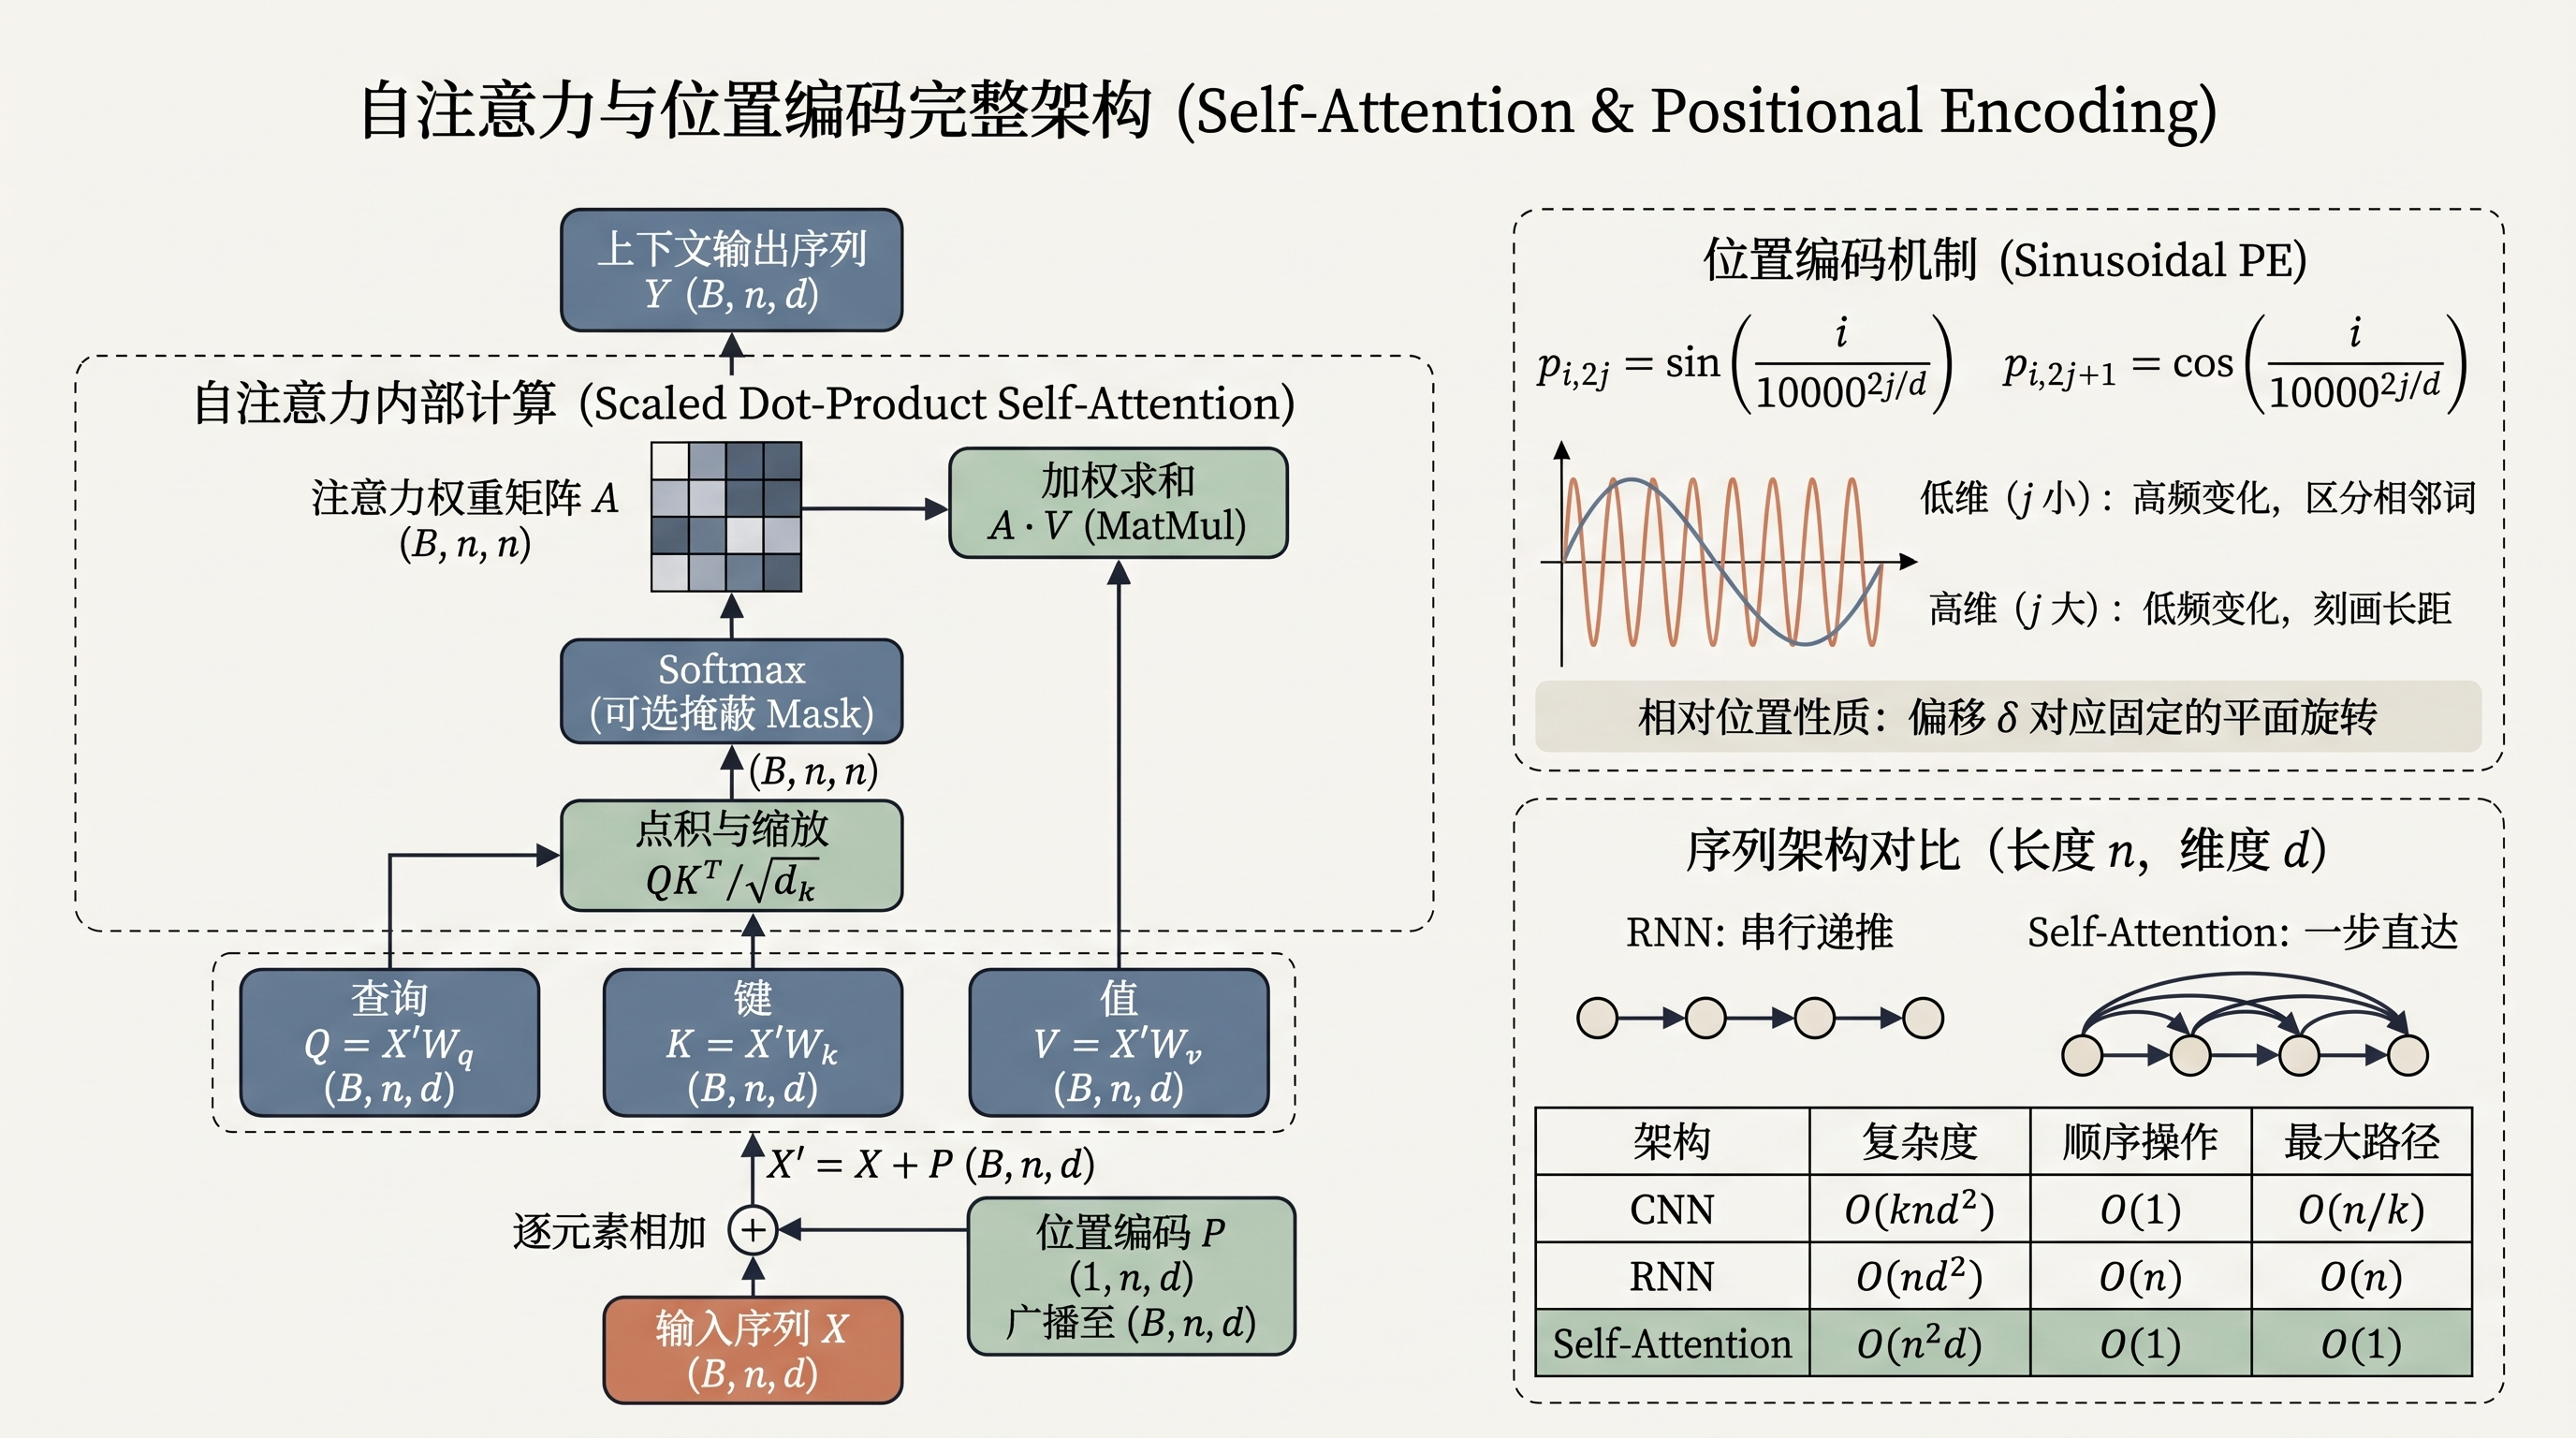

In [1]:
import math
import torch
from torch import nn
from d2l import torch as d2l

In [ ]:
num_hiddens, num_heads = 100, 5
attention = d2l.MultiHeadAttention(num_hiddens, num_hiddens, num_hiddens, num_hiddens, num_heads, 0.5)
attention.eval() # 多头注意力机制

MultiHeadAttention(
  (attention): DotProductAttention(
    (dropout): Dropout(p=0.5, inplace=False)
  )
  (W_q): Linear(in_features=100, out_features=100, bias=False)
  (W_k): Linear(in_features=100, out_features=100, bias=False)
  (W_v): Linear(in_features=100, out_features=100, bias=False)
  (W_o): Linear(in_features=100, out_features=100, bias=False)
)

- 批次：两个句子
- 查询次数：一个句子中的每个 Token 都会生成一个 Query，用它去寻找当前 Token 应该从其他 Token 中获取哪些信息。
- 有效长度：填充符不算

In [ ]:
batch_size, num_queries, valid_lens = 2, 4, torch.tensor([3, 2])
# 输入张量.shape(2,4,100）两个句子四 token 每个token的词表（词嵌入维度是100维）
X = torch.ones((batch_size, num_queries, num_hiddens))
attention(X, X, X, valid_lens).shape

torch.Size([2, 4, 100])

## 位置编码

In [ ]:
class PositionalEncoding(nn.Module):
    """位置编码"""
    def __init__(self, num_hiddens, dropout, max_len=1000):
        super(PositionalEncoding, self).__init__()
        self.dropout = nn.Dropout(dropout)
        # 创建一个足够长的P
        self.P = torch.zeros((1, max_len, num_hiddens))
        X = torch.arange(max_len, dtype=torch.float32).reshape(-1, 1) / torch.pow(10000, torch.arange(
            0, num_hiddens, 2, dtype=torch.float32) / num_hiddens)
        self.P[:, :, 0::2] = torch.sin(X)
        self.P[:, :, 1::2] = torch.cos(X)

    def forward(self, X):
        X = X + self.P[:, :X.shape[1], :].to(X.device)
        return self.dropout(X)


### 1. 计算目标

位置编码通过不同频率的正弦、余弦函数，为每个 Token 位置生成一个固定维度的向量。

$$
\boxed{
\begin{aligned}
P_{pos,2i}&=\sin\left(\frac{pos}{10000^{2i/d}}\right)\\
P_{pos,2i+1}&=\cos\left(\frac{pos}{10000^{2i/d}}\right)
\end{aligned}
}
$$

其中 $pos$ 是 Token 的位置索引，$d$ 是位置编码维度，$i$ 是正弦、余弦特征对的索引。

为了方便手算，设定：

- `max_len = 4`：一共生成 4 个位置的编码。
- `num_hiddens = 4`：每个位置的编码为 4 维。
- 正弦、余弦每两维组成一组，因此共有 $4/2=2$ 组。

### 2. 逐步计算角度矩阵 X

#### 2.1 生成位置编号（分子）

`torch.arange(max_len)` 生成：

$$
[0,1,2,3]
$$

经过 `.reshape(-1, 1)` 转换成列向量：

$$
\boxed{
A=
\begin{bmatrix}
0\\
1\\
2\\
3
\end{bmatrix}
}
$$

Shape：$(4,1)$。

#### 2.2 计算不同频率的分母

首先执行：

```python
torch.arange(0, num_hiddens, 2)
```

由于 `num_hiddens = 4`，得到：

$$
[0,2]
$$

然后除以 `num_hiddens`：

$$
\frac{[0,2]}{4}=[0,0.5]
$$

最后计算：

$$
10000^{[0,0.5]}=[10000^0,10000^{0.5}]
$$

得到：

$$
\boxed{B=[1,100]}
$$
pe：$(2,)$。

#### 2.3 广播相除，得到角度矩阵

将分子列向量 $A$ 与分母向量 $B$ 广播相除：

$$
X=\frac{A}{B}
$$

$$
X=
\begin{bmatrix}
\frac{0}{1}&\frac{0}{100}\\
\frac{1}{1}&\frac{1}{100}\\
\frac{2}{1}&\frac{2}{100}\\
\frac{3}{1}&\frac{3}{100}
\end{bmatrix}
$$

最终得到：

$$
\boxed{
X=
\begin{bmatrix}
0&0\\
1&0.01\\
2&0.02\\
3&0.03
\end{bmatrix}
}
$$

Shape：$(4,2)$。

**X 是角度矩阵，还不是最终的位置编码。** 每一行对应一个 Token 位置，每一列对应一组正弦、余弦函数使用的角度（单位为弧度）。

其通用表达式为：

$$
\boxed{X_{pos,i}=\frac{pos}{10000^{2i/d}}}
$$

### 3. 计算正弦与余弦

对应代码：

```python
self.P[:, :, 0::2] = torch.sin(X)
self.P[:, :, 1::2] = torch.cos(X)
```

其中 `0::2` 选择偶数索引维度（0、2），`1::2` 选择奇数索引维度（1、3）。

#### 3.1 计算 sin(X)

$$
\sin(X)=
\begin{bmatrix}
\sin(0)&\sin(0)\\
\sin(1)&\sin(0.01)\\
\sin(2)&\sin(0.02)\\
\sin(3)&\sin(0.03)
\end{bmatrix}
$$

数值近似为：

$$
\boxed{
\sin(X)\approx
\begin{bmatrix}
0&0\\
0.841&0.010\\
0.909&0.020\\
0.141&0.030
\end{bmatrix}
}
$$

#### 3.2 计算 cos(X)

$$
\cos(X)=
\begin{bmatrix}
\cos(0)&\cos(0)\\
\cos(1)&\cos(0.01)\\
\cos(2)&\cos(0.02)\\
\cos(3)&\cos(0.03)
\end{bmatrix}
$$

数值近似为：

$$
\boxed{
\cos(X)\approx
\begin{bmatrix}
1&1\\
0.540&1.000\\
-0.416&1.000\\
-0.990&1.000
\end{bmatrix}
}
$$

### 4. 交替填充最终位置编码矩阵 P

将 sin(X) 填入第 0、2 维，将 cos(X) 填入第 1、3 维。

因此：

$$
P_{pos}=
\left[
\sin(pos),
\cos(pos),
\sin\left(\frac{pos}{100}\right),
\cos\left(\frac{pos}{100}\right)
\right]
$$

最终得到：

$$
\boxed{
P\approx
\begin{bmatrix}
0&1&0&1\\
0.841&0.540&0.010&1.000\\
0.909&-0.416&0.020&1.000\\
0.141&-0.990&0.030&1.000
\end{bmatrix}
}
$$

矩阵每一行对应一个位置，每一列对应一个位置编码特征维度。

实际 PyTorch 张量保留最外层 Batch 广播维度，因此：

$$
\boxed{\operatorname{Shape}(P)=(1,4,4)}
$$

### 5. 与词嵌入相加

假设输入词嵌入为：

$$
X_{\text{input}}\in\mathbb{R}^{B\times4\times4}
$$

位置编码：

$$
P\in\mathbb{R}^{1\times4\times4}
$$

利用广播机制逐元素相加：

$$
\boxed{X'=X_{\text{input}}+P}
$$

最终：

$$
X'\in\mathbb{R}^{B\times4\times4}
$$

即每个 Token 的词向量都加上对应位置的位置编码，特征维度保持不变。训练时再经过 Dropout，得到位置编码模块的输出。

### 6. 核心结论

1. `arange` 生成位置编号与特征维度索引。
2. `torch.pow` 计算不同频率对应的分母。
3. 广播相除得到角度矩阵 $X$。
4. 分别对 $X$ 计算 sin 和 cos，并交替填入位置编码矩阵 $P$。
5. 将 $P$ 与词嵌入逐元素相加，为每个 Token 注入位置信息。

当 `max_len = 1000`、`num_hiddens = 100` 时：

$$
\boxed{\operatorname{Shape}(X)=(1000,50)}
$$

$$
\boxed{\operatorname{Shape}(P)=(1,1000,100)}
$$

**本质：先计算所有位置在不同频率下的角度，再用 sin、cos 将这些角度转换为固定的位置特征向量。**

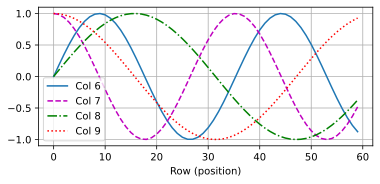

In [6]:
encoding_dim, num_steps = 32, 60
pos_encoding = PositionalEncoding(encoding_dim, 0)
pos_encoding.eval()
X = pos_encoding(torch.zeros((1, num_steps, encoding_dim)))
P = pos_encoding.P[:, :X.shape[1], :]
d2l.plot(torch.arange(num_steps), P[0, :, 6:10].T, xlabel='Row (position)',
         figsize=(6, 2.5), legend=["Col %d" % d for d in torch.arange(6, 10)])

为了理解位置编码中**不同特征维度的频率逐渐降低与绝对位置信息之间的关系**，我们可以观察整数的二进制表示。可以发现，最低位的比特值每隔 1 个数字交替变化一次，第二位每隔 2 个数字交替变化一次，第三位则每隔 4 个数字交替变化一次。这说明不同二进制位具有不同的变化频率，与正弦位置编码中不同特征维度的频率变化规律类似。

In [7]:
for i in range(8):
    print(f'{i}的二进制是：{i:>03b}')

0的二进制是：000
1的二进制是：001
2的二进制是：010
3的二进制是：011
4的二进制是：100
5的二进制是：101
6的二进制是：110
7的二进制是：111


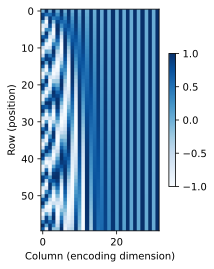

In [8]:
P = P[0, :, :].unsqueeze(0).unsqueeze(0)
d2l.show_heatmaps(P, xlabel='Column (encoding dimension)',
                  ylabel='Row (position)', figsize=(3.5, 4), cmap='Blues')